# Workout intensity: data analysis

This notebook examines `train.csv` and `test.csv`, then estimates which columns help predict `intensity` (`easy`, `moderate`, `hard`). Run all cells from the project root or from `Data/`. The charts and tables below are generated from the CSV files; no test labels are assumed.

**How importance is measured.** A random forest is trained on an 80/20 stratified split of the training set. Each original input column is shuffled in the held-out set and the drop in **balanced accuracy** is measured. A large positive drop means the model relies on that column. A near-zero drop means it adds little *given the other columns in this model*; correlated columns may substitute for each other. This is predictive evidence, not causality. `workout_id` is excluded because it is only a row identifier. `user_id` is retained as a category because all test users occur in training; it may encode personal baselines, but this would not transfer to unseen users.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import balanced_accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_rows", 100)

data_dir = Path("Data") if Path("Data/train.csv").exists() else Path(".")
train_raw = pd.read_csv(data_dir / "train.csv")
test_raw = pd.read_csv(data_dir / "test.csv")
submission = pd.read_csv(data_dir / "sample_submission.csv")
classes = ["easy", "moderate", "hard"]
print(f"Train: {train_raw.shape[0]:,} rows × {train_raw.shape[1]} columns")
print(f"Test:  {test_raw.shape[0]:,} rows × {test_raw.shape[1]} columns")
print(f"Sample submission: {submission.shape[0]:,} rows × {submission.shape[1]} columns")
print(f"Train users: {train_raw.user_id.nunique()}, test users: {test_raw.user_id.nunique()}, shared: {len(set(train_raw.user_id) & set(test_raw.user_id))}")

Train: 22,728 rows × 18 columns
Test:  7,669 rows × 17 columns
Sample submission: 7,669 rows × 2 columns
Train users: 183, test users: 183, shared: 183


## 1. Structure and quality

The table checks types, missing values, distinct values, and numeric ranges in both datasets. `altitude_mean_m = -9999` is treated as an invalid sentinel in later plots and modeling. Other extreme values are shown rather than silently removed.

In [2]:
assert train_raw.columns.drop("intensity").tolist() == test_raw.columns.tolist()
assert train_raw.workout_id.is_unique and test_raw.workout_id.is_unique
assert set(train_raw.workout_id).isdisjoint(test_raw.workout_id)
assert train_raw.intensity.notna().all()

audit = pd.DataFrame({
    "type": train_raw.dtypes.astype(str),
    "train missing": train_raw.isna().sum(),
    "test missing": test_raw.isna().sum().reindex(train_raw.columns),
    "distinct in train": train_raw.nunique(),
    "train min": train_raw.select_dtypes("number").min(),
    "train median": train_raw.select_dtypes("number").median(),
    "train max": train_raw.select_dtypes("number").max(),
}).fillna("")
display(audit)
print("Exact duplicate training rows:", train_raw.duplicated().sum())
print("Invalid -9999 altitude_mean_m values — train/test:",
      (train_raw.altitude_mean_m == -9999).sum(),
      (test_raw.altitude_mean_m == -9999).sum())
print("GPS point values at the 500 cap — train/test:",
      (train_raw.n_points == 500).mean().round(3),
      (test_raw.n_points == 500).mean().round(3))

train = train_raw.copy()
test = test_raw.copy()
for frame in (train, test):
    frame.loc[frame.altitude_mean_m == -9999, "altitude_mean_m"] = np.nan

,type,train missing,test missing,distinct in train,train min,train median,train max
altitude_gain_m,float64,0,0.0,1320,0.0,147.0,20270.0
altitude_loss_m,float64,0,0.0,1283,-0.0,147.0,20178.0
altitude_mean_m,float64,0,0.0,1179,-9999.0,56.0,12166.0
distance_km,float64,0,0.0,6871,0.2,14.95,176.76
duration_min,float64,0,0.0,2675,5.0,62.2,359.8
gender,object,0,0.0,3,,,
intensity,object,0,,3,,,
max_speed_kmh,float64,0,0.0,590,0.0,28.3,115.6
month,int64,0,0.0,12,1.0,7.0,12.0
n_points,int64,0,0.0,457,23.0,500.0,500.0


Exact duplicate training rows: 0
Invalid -9999 altitude_mean_m values — train/test: 2 1
GPS point values at the 500 cap — train/test: 0.773 0.767


## 2. Target balance and train/test composition

Class balance is important for interpreting the baseline. The sport mix shows whether training and test are drawn from similar populations.

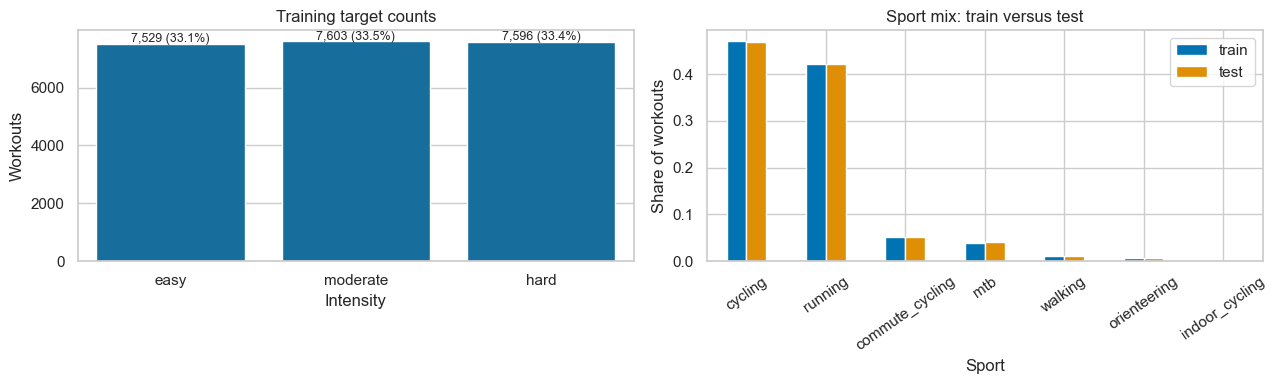

intensity,easy,moderate,hard
sport,,,
commute_cycling,0.331,0.338,0.330
cycling,0.332,0.336,0.332
indoor_cycling,0.286,0.286,0.429
mtb,0.338,0.332,0.330
orienteering,0.331,0.339,0.331
running,0.330,0.332,0.337
walking,0.329,0.337,0.333


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts = train.intensity.value_counts().reindex(classes)
sns.barplot(x=counts.index, y=counts.values, ax=ax[0])
ax[0].set(title="Training target counts", xlabel="Intensity", ylabel="Workouts")
for i, n in enumerate(counts):
    ax[0].text(i, n + 50, f"{n:,} ({n / len(train):.1%})", ha="center", fontsize=9)
sport_mix = pd.DataFrame({
    "train": train.sport.value_counts(normalize=True),
    "test": test.sport.value_counts(normalize=True),
}).fillna(0).sort_values("train", ascending=False)
sport_mix.plot.bar(ax=ax[1], color=sns.color_palette("colorblind", 2))
ax[1].set(title="Sport mix: train versus test", xlabel="Sport", ylabel="Share of workouts")
ax[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()
display(pd.crosstab(train.sport, train.intensity, normalize="index").reindex(columns=classes).round(3))

## 3. Numerical patterns by intensity

The boxplots separate running and cycling, because a speed that is high for running can be ordinary for cycling. Whiskers omit plotted outliers for readability; all records remain in the analysis.

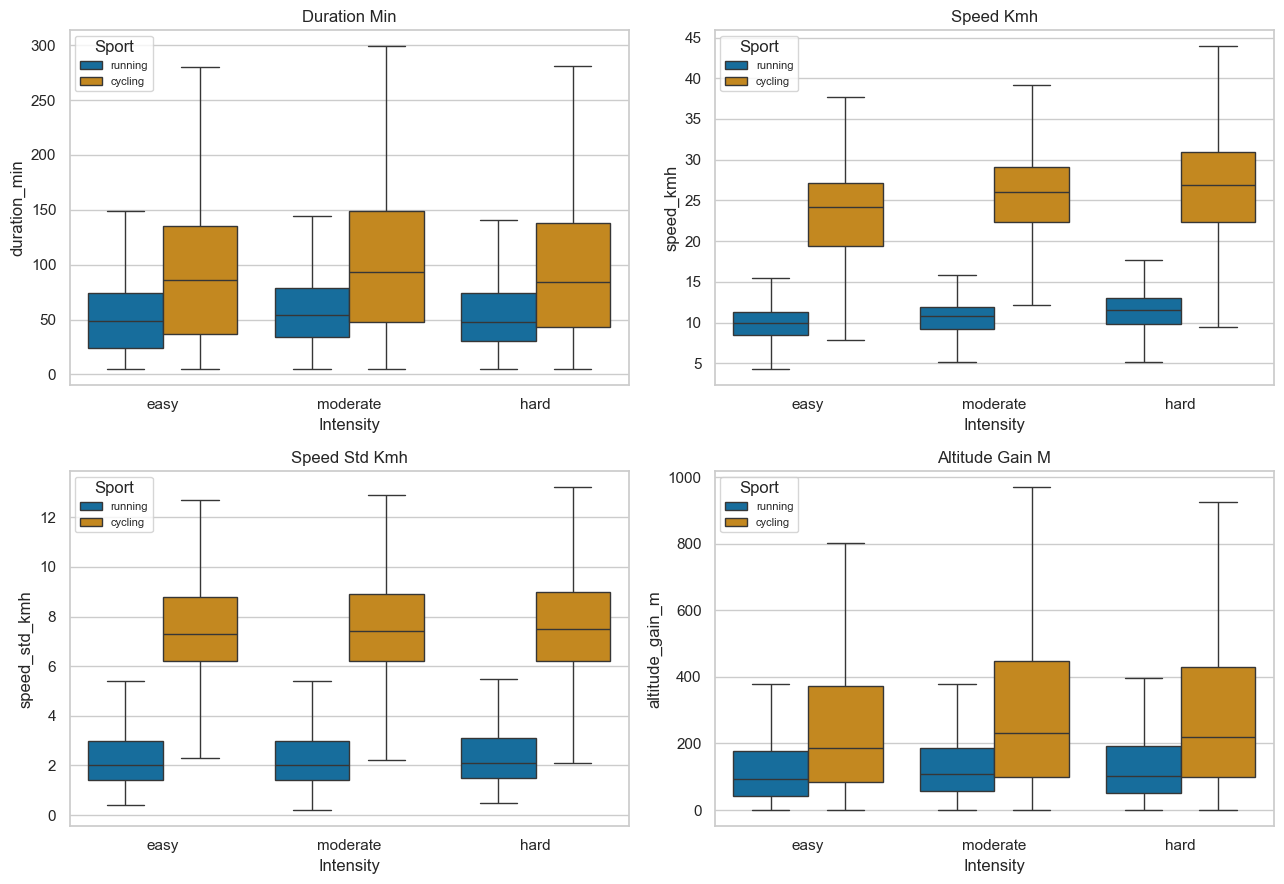

In [4]:
features_to_plot = ["duration_min", "speed_kmh", "speed_std_kmh", "altitude_gain_m"]
major = train[train.sport.isin(["running", "cycling"])]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for feature, ax in zip(features_to_plot, axes.flat):
    sns.boxplot(data=major, x="intensity", y=feature, hue="sport",
                order=classes, showfliers=False, ax=ax)
    ax.set(title=feature.replace("_", " ").title(), xlabel="Intensity")
    ax.legend(title="Sport", fontsize=8)
plt.tight_layout()
plt.show()

## 4. Categorical and calendar columns

Each heatmap row sums to 100%. This is a *marginal* relationship: it does not control for the user's usual workouts or for other columns.

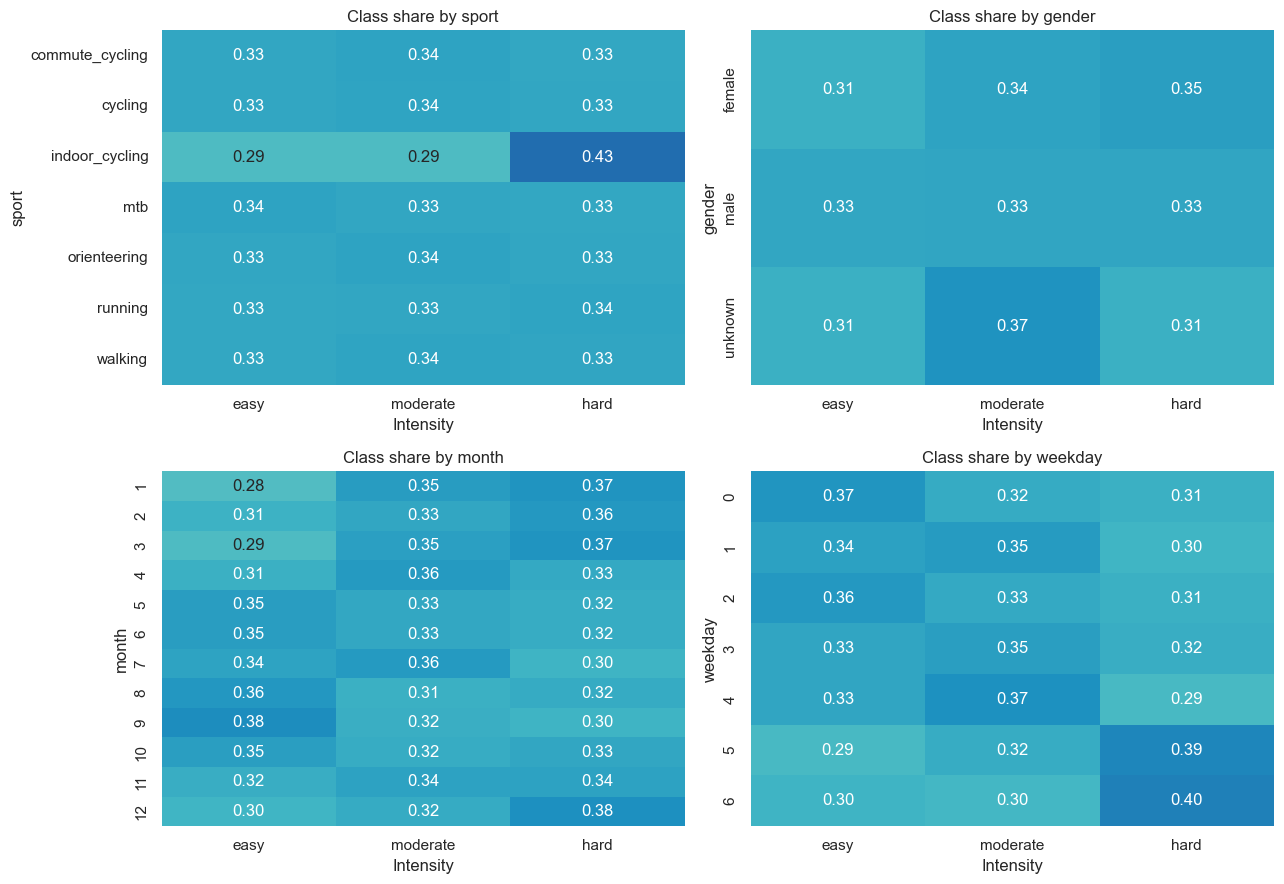

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for col, ax in zip(["sport", "gender", "month", "weekday"], axes.flat):
    rate = pd.crosstab(train[col], train.intensity, normalize="index").reindex(columns=classes)
    sns.heatmap(rate, annot=True, fmt=".2f", vmin=0, vmax=0.6,
                cmap="YlGnBu", cbar=False, ax=ax)
    ax.set(title=f"Class share by {col}", xlabel="Intensity", ylabel=col)
plt.tight_layout()
plt.show()

## 5. Redundant numerical columns

Strong correlations mean that shuffling one column may have a small effect because another column supplies similar information. Correlation also helps identify candidate feature groups for later model experiments.

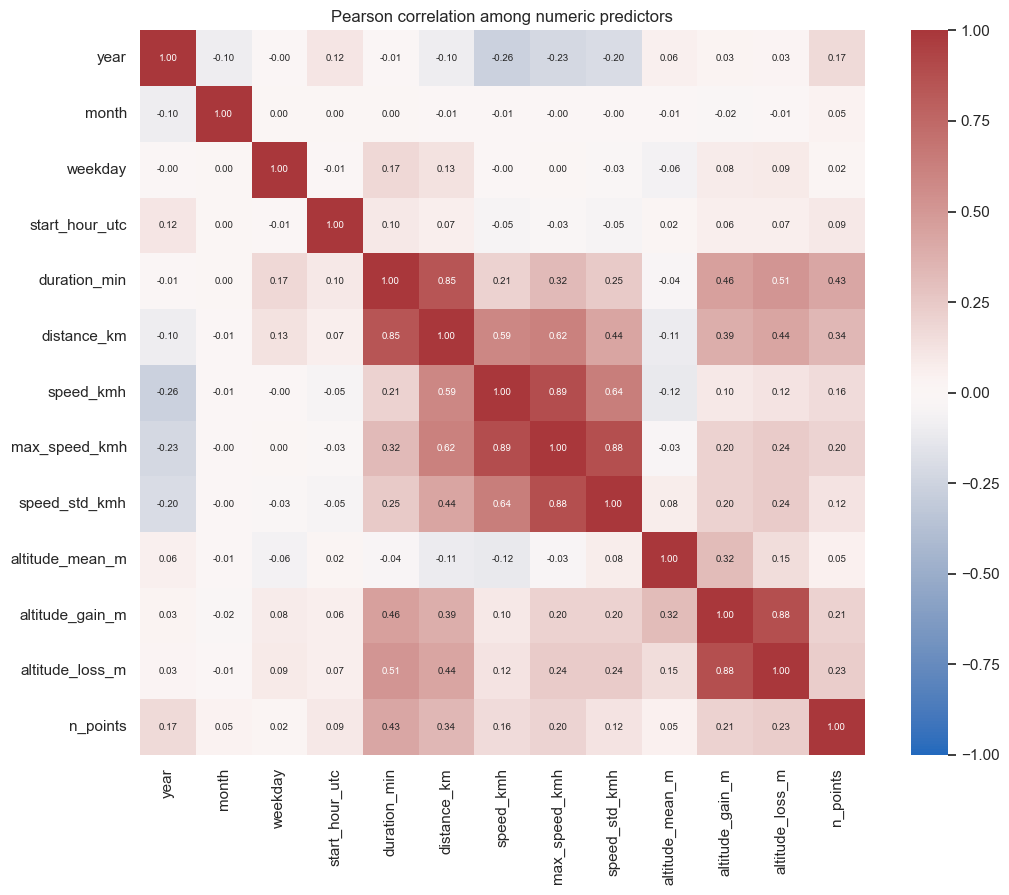

absolute correlation
speed_kmh       max_speed_kmh                0.890126
altitude_gain_m altitude_loss_m              0.879423
max_speed_kmh   speed_std_kmh                0.875633
duration_min    distance_km                  0.848372
speed_kmh       speed_std_kmh                0.640376
distance_km     max_speed_kmh                0.622003
                speed_kmh                    0.589368
duration_min    altitude_loss_m              0.508657
                altitude_gain_m              0.457275
distance_km     speed_std_kmh                0.437273

In [6]:
numeric_cols = [c for c in train.select_dtypes("number") if c not in ["workout_id", "user_id"]]
corr = train[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", square=True, annot_kws={"fontsize": 7}, ax=ax)
ax.set_title("Pearson correlation among numeric predictors")
plt.tight_layout()
plt.show()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
display(upper.abs().sort_values(ascending=False).head(10).rename("absolute correlation").to_frame())

## 6. Held-out predictive importance

The split is stratified by intensity and fixed with seed 42. A workout-level split matches this dataset's test situation, where the same users are present in both datasets. The dummy baseline predicts the most common class. The forest handles non-linear relations; categorical variables are one-hot encoded. All preprocessing is fitted only on the training fold.

Dummy balanced accuracy:  0.333
Forest balanced accuracy: 0.548
              precision    recall  f1-score   support

        easy       0.58      0.65      0.61      1506
    moderate       0.46      0.42      0.44      1521
        hard       0.60      0.57      0.59      1519

    accuracy                           0.55      4546
   macro avg       0.54      0.55      0.55      4546
weighted avg       0.54      0.55      0.55      4546



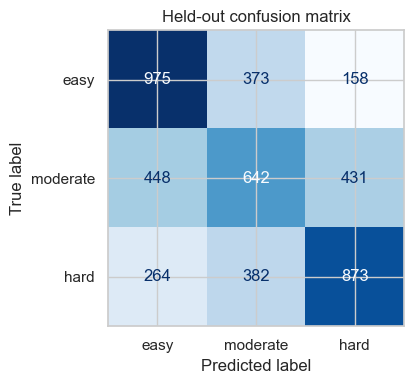

In [7]:
feature_cols = [c for c in test.columns if c != "workout_id"]
categorical_cols = ["user_id", "sport", "gender"]
numeric_model_cols = [c for c in feature_cols if c not in categorical_cols]
X = train[feature_cols]
y = train.intensity
X_fit, X_val, y_fit, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_model_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
])
model = Pipeline([
    ("preprocess", preprocess),
    ("forest", RandomForestClassifier(n_estimators=120, min_samples_leaf=3,
                                      random_state=42, n_jobs=-1)),
])
model.fit(X_fit, y_fit)
pred = model.predict(X_val)
dummy = DummyClassifier(strategy="most_frequent").fit(X_fit, y_fit)
baseline_score = balanced_accuracy_score(y_val, dummy.predict(X_val))
model_score = balanced_accuracy_score(y_val, pred)
print(f"Dummy balanced accuracy:  {baseline_score:.3f}")
print(f"Forest balanced accuracy: {model_score:.3f}")
print(classification_report(y_val, pred, labels=classes, zero_division=0))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_val, pred, labels=classes,
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Held-out confusion matrix")
plt.tight_layout()
plt.show()

### Permutation importance

Each column is shuffled **three times** on a fixed 2,000-row subset of the held-out fold. The bars show mean loss in balanced accuracy; error bars show variation across the three shuffles. Values at or below zero have no demonstrated contribution in this check. Do not interpret the ranking as a causal effect or a permanent reason to delete a correlated feature.

,column,mean accuracy drop,shuffle sd
0,speed_kmh,0.0619,0.0034
1,user_id,0.0511,0.0042
2,max_speed_kmh,0.0440,0.0039
3,year,0.0315,0.0049
4,sport,0.0293,0.0028
5,duration_min,0.0237,0.0013
6,month,0.0222,0.0006
7,distance_km,0.0201,0.0035
8,speed_std_kmh,0.0185,0.0035
9,start_hour_utc,0.0183,0.0056


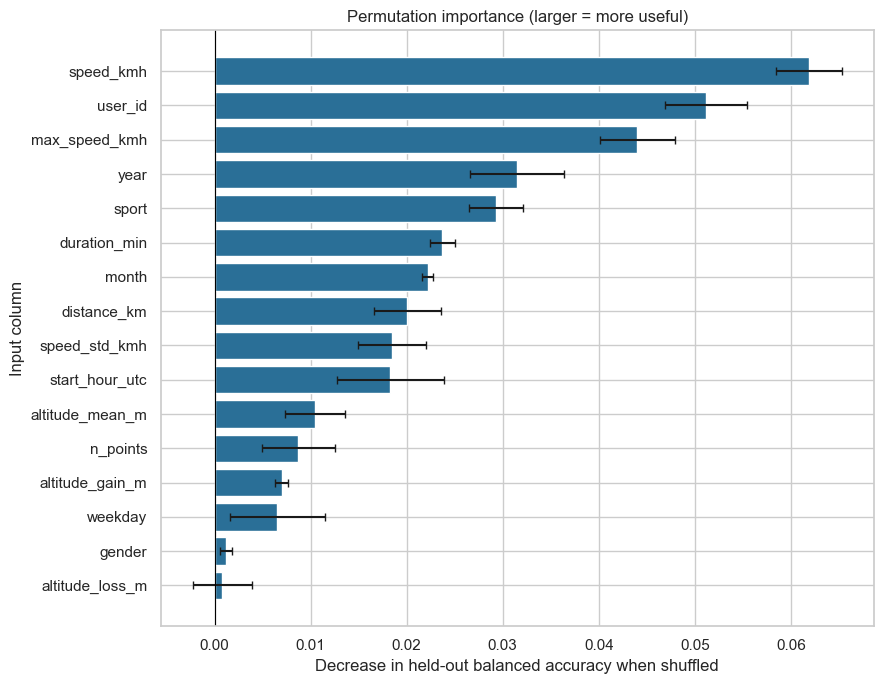

In [8]:
probe_idx = X_val.sample(n=min(2000, len(X_val)), random_state=42).index
X_probe, y_probe = X_val.loc[probe_idx], y_val.loc[probe_idx]
result = permutation_importance(
    model, X_probe, y_probe, scoring="balanced_accuracy",
    n_repeats=3, random_state=42, n_jobs=1,
)
importance = pd.DataFrame({
    "column": feature_cols,
    "mean accuracy drop": result.importances_mean,
    "shuffle sd": result.importances_std,
}).sort_values("mean accuracy drop", ascending=False).reset_index(drop=True)
display(importance.style.format({"mean accuracy drop": "{:.4f}", "shuffle sd": "{:.4f}"}))
fig, ax = plt.subplots(figsize=(9, 7))
plot = importance.sort_values("mean accuracy drop")
ax.barh(plot.column, plot["mean accuracy drop"], xerr=plot["shuffle sd"],
        color="#2A6F97", capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Decrease in held-out balanced accuracy when shuffled",
       ylabel="Input column", title="Permutation importance (larger = more useful)")
plt.tight_layout()
plt.show()

## 7. Interpretation and next modeling steps

The following summary is generated from the measured importance table. It deliberately calls near-zero columns **lower priority**, since correlated inputs can mask each other's individual importance. Retrain and compare validation scores before permanently dropping any non-ID column.

In [9]:
top = importance.head(5).column.tolist()
low = importance.loc[importance["mean accuracy drop"] <= 0.002, "column"].tolist()
above = importance.loc[importance["mean accuracy drop"] > 0.002, "column"].tolist()
display(Markdown((chr(10) * 2).join([
    f"**Most useful in this model:** {', '.join(f'`{x}`' for x in top)}.",
    "**Lower priority in this check (drop <= 0.002):** "
    + (', '.join(f'`{x}`' for x in low) if low else 'none') + ".",
    f"**Held-out balanced accuracy:** {model_score:.3f} versus {baseline_score:.3f} for the dummy baseline.",
])))
print("Columns with a measured drop above 0.002:", ", ".join(above))
print("For a leaner model: remove workout_id, then ablate low-priority columns and refit on the same split.")
print("Check correlated groups together (speed / max speed / speed variability, altitude gain / loss, duration / distance).")
print("Keep user_id only if future predictions concern users already represented in training.")
print("The sample submission is a format example, not ground truth for test labels.")

**Most useful in this model:** `speed_kmh`, `user_id`, `max_speed_kmh`, `year`, `sport`.

**Lower priority in this check (drop <= 0.002):** `gender`, `altitude_loss_m`.

**Held-out balanced accuracy:** 0.548 versus 0.333 for the dummy baseline.

Columns with a measured drop above 0.002: speed_kmh, user_id, max_speed_kmh, year, sport, duration_min, month, distance_km, speed_std_kmh, start_hour_utc, altitude_mean_m, n_points, altitude_gain_m, weekday
For a leaner model: remove workout_id, then ablate low-priority columns and refit on the same split.
Check correlated groups together (speed / max speed / speed variability, altitude gain / loss, duration / distance).
Keep user_id only if future predictions concern users already represented in training.
The sample submission is a format example, not ground truth for test labels.
